# Import Libraries

In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report , accuracy_score , confusion_matrix

In [2]:
df = pd.read_csv(r'/kaggle/input/luflow-network-intrusion-detection-data-set/2020/10/2020.10.01/2020.10.01.csv')
df.head()

,avg_ipt,bytes_in,bytes_out,dest_ip,dest_port,entropy,num_pkts_out,num_pkts_in,proto,src_ip,src_port,time_end,time_start,total_entropy,label,duration
0,0.0,0,14480,786,9200.0,2.116894,10,0,6,786,43432.0,1601521393115058,1601521393114933,30652.621,benign,0.000125
1,0.0,0,7240,786,9200.0,3.748675,5,0,6,786,43428.0,1601521393115613,1601521393115579,27140.404,benign,0.000034
2,0.0,0,14480,786,9200.0,2.079622,10,0,6,786,43436.0,1601521393116141,1601521393115993,30112.930,benign,0.000148
3,0.0,0,14480,786,9200.0,2.033979,10,0,6,786,43434.0,1601521393116629,1601521393116562,29452.021,benign,0.000067
4,0.0,0,14480,786,9200.0,1.955485,10,0,6,786,43434.0,1601521393116743,1601521393116635,28315.428,benign,0.000108


In [3]:
df.shape

(1081952, 16)

In [4]:
df.columns

Index(['avg_ipt', 'bytes_in', 'bytes_out', 'dest_ip', 'dest_port', 'entropy',
       'num_pkts_out', 'num_pkts_in', 'proto', 'src_ip', 'src_port',
       'time_end', 'time_start', 'total_entropy', 'label', 'duration'],
      dtype='object')

avg_ipt: The average inter-packet time, indicating the average time between consecutive packets in a network flow.



bytes_in: The total number of bytes received by the destination (incoming traffic) in the flow.



bytes_out: The total number of bytes sent from the source (outgoing traffic) in the flow.



dest_ip: The IP address of the destination (receiving endpoint) in the network flow.



dest_port: The destination port number associated with the flow, typically indicating the service or application (e.g., HTTP, SSH).



entropy: A measure of randomness or unpredictability in the data, possibly applied to packet contents or communication patterns.



num_pkts_out: The total number of packets sent from the source to the destination during the flow.


    
num_pkts_in: The total number of packets received by the destination from the source during the flow.



proto: The protocol used for the flow (e.g., TCP, UDP, ICMP).



src_ip: The IP address of the source (sending endpoint) in the network flow.


    
src_port: The source port number associated with the flow, typically indicating the application's origin on the sender's side.



time_end: The timestamp indicating the end of the network flow.


    
time_start: The timestamp indicating the start of the network flow.



total_entropy: The overall measure of entropy for the entire flow, potentially combining packet-level or session-level randomness metrics.


    
label: The classification or tag for the flow, such as normal or anomalous, or specific categories like malware or benign.


    
duration: The total time duration of the flow, calculated as time_end - time_start.

In [5]:
# check nulls
df.isna().sum()

avg_ipt              0
bytes_in             0
bytes_out            0
dest_ip              0
dest_port        13264
entropy              0
num_pkts_out         0
num_pkts_in          0
proto                0
src_ip               0
src_port         13264
time_end             0
time_start           0
total_entropy        0
label                0
duration             0
dtype: int64

In [6]:
# Impute nulls
df['dest_port'] = df['dest_port'].fillna(-1)
df['src_port'] = df['src_port'].fillna(-1)

In [7]:
df.isna().sum()

avg_ipt          0
bytes_in         0
bytes_out        0
dest_ip          0
dest_port        0
entropy          0
num_pkts_out     0
num_pkts_in      0
proto            0
src_ip           0
src_port         0
time_end         0
time_start       0
total_entropy    0
label            0
duration         0
dtype: int64

In [8]:
df.describe()

,avg_ipt,bytes_in,bytes_out,dest_ip,dest_port,entropy,num_pkts_out,num_pkts_in,proto,src_ip,src_port,time_end,time_start,total_entropy,duration
count,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06,1.081952e+06
mean,1.438714e+06,4.182185e+02,2.354654e+03,4.163730e+03,1.200858e+04,3.048347e+00,5.344491e+00,3.058727e+00,6.432499e+00,2.008594e+04,3.887982e+04,1.456847e+15,1.456233e+15,8.498996e+03,9.590423e-01
std,4.090331e+07,2.085036e+03,5.891802e+03,2.054663e+04,1.663640e+04,2.287969e+00,1.846022e+01,1.101436e+01,2.356546e+00,4.544084e+04,2.011522e+04,4.357679e+14,4.365854e+14,1.762607e+04,4.219283e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,3.000000e+00,-1.000000e+00,1.601515e+10,1.601521e+10,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00,7.860000e+02,4.450000e+02,0.000000e+00,1.000000e+00,0.000000e+00,6.000000e+00,7.860000e+02,2.494100e+04,1.601522e+15,1.601522e+15,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,1.910000e+02,7.860000e+02,9.200000e+03,3.762122e+00,2.000000e+00,1.000000e+00,6.000000e+00,7.860000e+02,4.343200e+04,1.601525e+15,1.601525e+15,2.105241e+03,1.690000e-04
75%,3.075000e+01,2.700000e+02,1.452000e+03,7.860000e+02,9.200000e+03,4.726709e+00,6.000000e+00,2.000000e+00,6.000000e+00,1.797400e+04,5.366100e+04,1.601538e+15,1.601538e+15,1.241337e+04,1.267920e-01
max,4.294967e+09,6.456800e+04,6.553200e+04,3.987220e+05,6.553500e+04,3.408484e+01,2.550000e+02,2.540000e+02,4.700000e+01,3.987220e+05,6.553500e+04,1.601597e+15,1.601597e+15,1.839968e+06,4.202127e+01


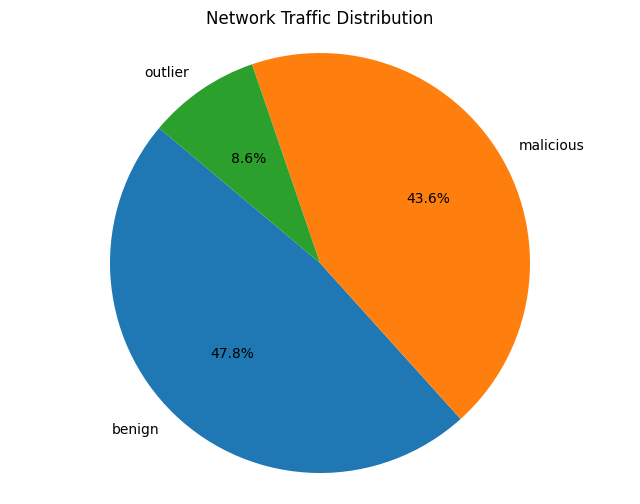

In [9]:
plt.figure(figsize=(8, 6))
plt.pie(df['label'].value_counts().values, labels=df['label'].value_counts().index,   autopct='%1.1f%%', startangle=140)
plt.title('Network Traffic Distribution')
plt.axis('equal')  # Equal aspect ratio ensures the pie is a circle.
plt.show()

# Split

In [10]:
# split to features & label
x = df.drop(columns = ['label'] , axis =1)
y = df['label']

In [15]:
# split to train & test usinf stratify for unbalancing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42 , stratify=y)

# Encode label

In [16]:
encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

# Build model

In [17]:
# build RandomForest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
# Fit the model to the training data
rf_model.fit(x_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [18]:
# predict on train data
y_pred_train = rf_model.predict(x_train)

In [19]:
# Accuracy on train
print("Accuracy of train data:", accuracy_score(y_train, y_pred_train))

Accuracy of train data: 0.9999838255189409


In [20]:
# Classification report of train data
print("Classification Report:\n", classification_report(y_train, y_pred_train))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    413594
           1       1.00      1.00      1.00    377181
           2       1.00      1.00      1.00     74786

    accuracy                           1.00    865561
   macro avg       1.00      1.00      1.00    865561
weighted avg       1.00      1.00      1.00    865561



# Prediction

In [21]:
# predict on test data
y_pred_test = rf_model.predict(x_test)

#Accuracy on test data
print("Accuracy:", accuracy_score(y_test, y_pred_test))


Accuracy: 0.9989509730071953


In [22]:
# classification report of test data
print("Classification Report:\n", classification_report(y_test, y_pred_test))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    103399
           1       1.00      1.00      1.00     94295
           2       1.00      0.99      0.99     18697

    accuracy                           1.00    216391
   macro avg       1.00      1.00      1.00    216391
weighted avg       1.00      1.00      1.00    216391



In [25]:
# show actual vs. prediction
df_results = pd.DataFrame({
    'y_test': y_test,
    'y_pred': y_pred_test
})

df_results

,y_test,y_pred
0,1,1
1,0,0
2,1,1
3,1,1
4,0,0
...,...,...
216386,1,1
216387,0,0
216388,1,1
216389,1,1


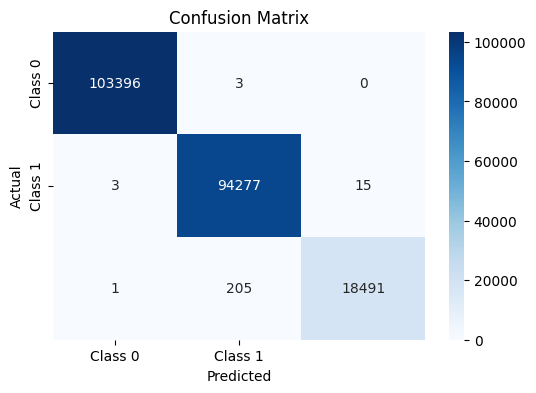

In [30]:
# show confusion matrix of test data
cm = confusion_matrix(y_test , y_pred_test)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()